# 2. Análisis Exploratorio de Datos (EDA)

**Objetivo:** identificar patrones y relaciones entre las variables y la supervivencia.

Preguntas guía:
1. ¿Qué proporción sobrevivió? ¿Las clases están balanceadas?
2. ¿Influyen el sexo, la clase y la edad?
3. ¿Viajar solo o en familia cambia la probabilidad de sobrevivir?
4. ¿Qué variables numéricas se correlacionan más con `Survived`?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (8, 4.5)

df = pd.read_csv("data/titanic_clean.csv")
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df.head()

,PassengerId,Survived,Pclass,Name,Title,Sex,Age,AgeWasMissing,SibSp,Parch,Ticket,Fare,Deck,HasCabin,Embarked,FamilySize
0,1,0,3,"Braund, Mr. Owen Harris",Mr,male,22.0,0,1,0,A/5 21171,7.2500,U,0,S,2
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,female,38.0,0,1,0,PC 17599,71.2833,C,1,C,2
2,3,1,3,"Heikkinen, Miss. Laina",Miss,female,26.0,0,0,0,STON/O2. 3101282,7.9250,U,0,S,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,female,35.0,0,1,0,113803,53.1000,C,1,S,2
4,5,0,3,"Allen, Mr. William Henry",Mr,male,35.0,0,0,0,373450,8.0500,U,0,S,1


## 2.1 Variable objetivo

Survived
No sobrevivió    61.6
Sobrevivió       38.4
Name: proportion, dtype: float64


/tmp/ipykernel_508/1046603218.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["No sobrevivió", "Sobrevivió"])


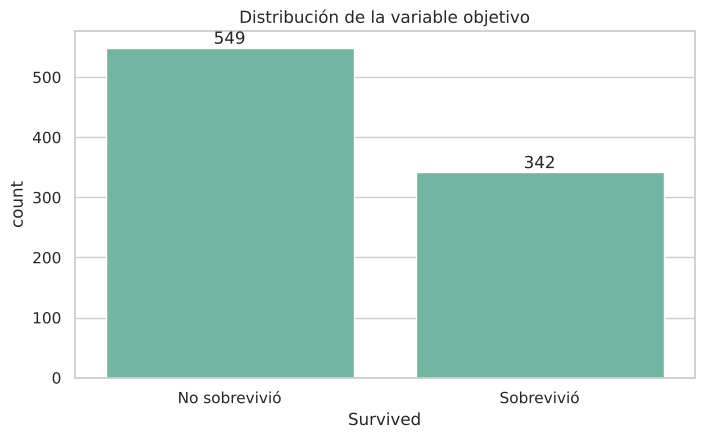

In [2]:
tasa = df["Survived"].value_counts(normalize=True).rename({0: "No sobrevivió", 1: "Sobrevivió"})
print((tasa * 100).round(1))

ax = sns.countplot(data=df, x="Survived")
ax.set_xticklabels(["No sobrevivió", "Sobrevivió"])
ax.set_title("Distribución de la variable objetivo")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.show()

Aproximadamente **62 % no sobrevivió y 38 % sí**. Es un desbalance moderado: por eso no basta con la exactitud y también mediremos **sensibilidad, especificidad y AUC-ROC**, y usaremos particiones **estratificadas**.

## 2.2 Sexo, clase y puerto de embarque

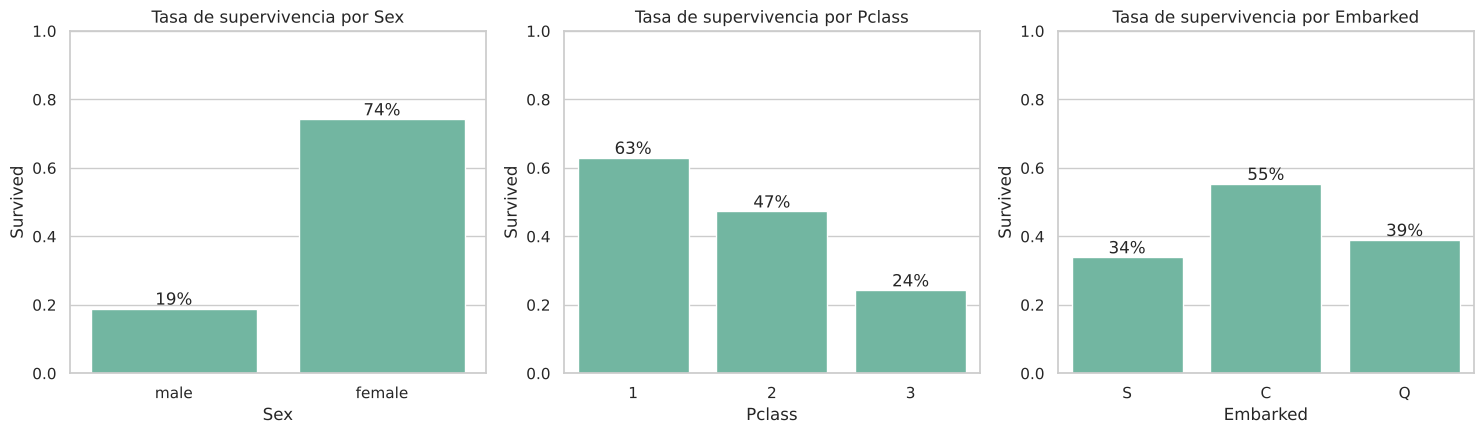

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    sns.barplot(data=df, x=col, y="Survived", ax=ax, errorbar=None)
    ax.set_title(f"Tasa de supervivencia por {col}")
    ax.set_ylim(0, 1)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.0%}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()

In [4]:
pd.crosstab([df["Sex"], df["Pclass"]], df["Survived"], normalize="index").round(3) * 100

Survived          0     1
Sex    Pclass            
female 1        3.2  96.8
       2        7.9  92.1
       3       50.0  50.0
male   1       63.1  36.9
       2       84.3  15.7
       3       86.5  13.5

**Hallazgos:**
- El **sexo** es el factor más fuerte: las mujeres sobreviven mucho más que los hombres ("mujeres y niños primero").
- La **clase** importa: primera clase sobrevive bastante más que tercera.
- Combinadas, las mujeres de 1.ª y 2.ª clase casi siempre sobreviven; los hombres de 2.ª y 3.ª clase casi nunca.
- Cherbourg (C) muestra mayor supervivencia, probablemente porque ahí embarcó más gente de primera clase (efecto confusor).

In [5]:
pd.crosstab(df["Embarked"], df["Pclass"], normalize="index").round(2)

Pclass,1,2,3
Embarked,,,
C,0.51,0.10,0.39
Q,0.03,0.04,0.94
S,0.20,0.25,0.55


## 2.3 Edad

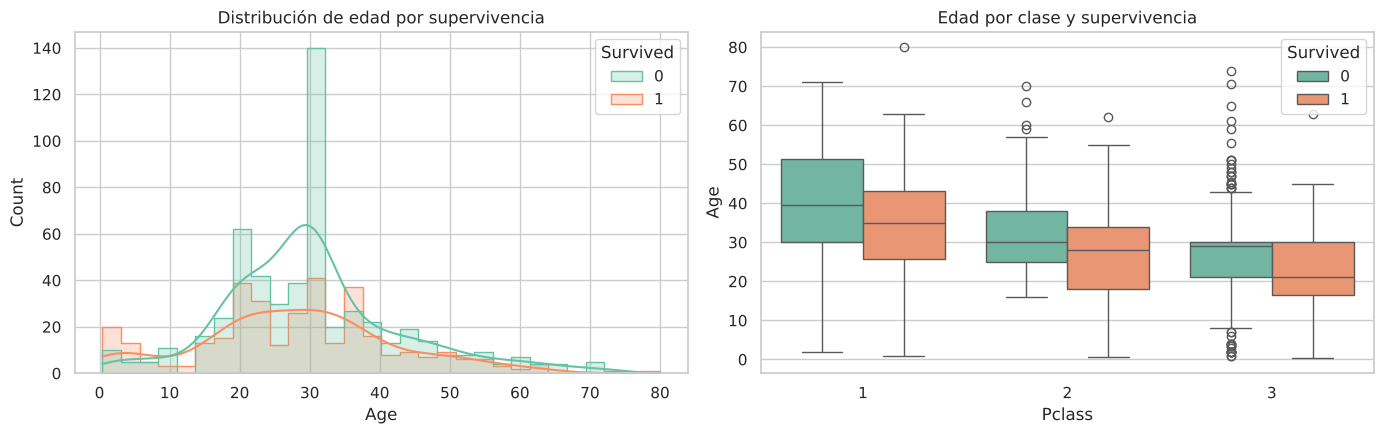

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, ax=axes[0], element="step")
axes[0].set_title("Distribución de edad por supervivencia")
sns.boxplot(data=df, x="Pclass", y="Age", hue="Survived", ax=axes[1])
axes[1].set_title("Edad por clase y supervivencia")
plt.tight_layout(); plt.show()

In [7]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[-1, 12, 18, 35, 60, 120],
                        labels=["Niño (0-12)", "Adolescente (13-18)", "Joven (19-35)", "Adulto (36-60)", "Mayor (60+)"])
df.groupby("AgeGroup", observed=True)["Survived"].agg(["mean", "count"]).round(3)

,mean,count
AgeGroup,,
Niño (0-12),0.575,73
Adolescente (13-18),0.429,70
Joven (19-35),0.353,530
Adulto (36-60),0.398,196
Mayor (60+),0.227,22


Los **niños** tienen la tasa de supervivencia más alta; los mayores de 60, la más baja.

## 2.4 Tarifa

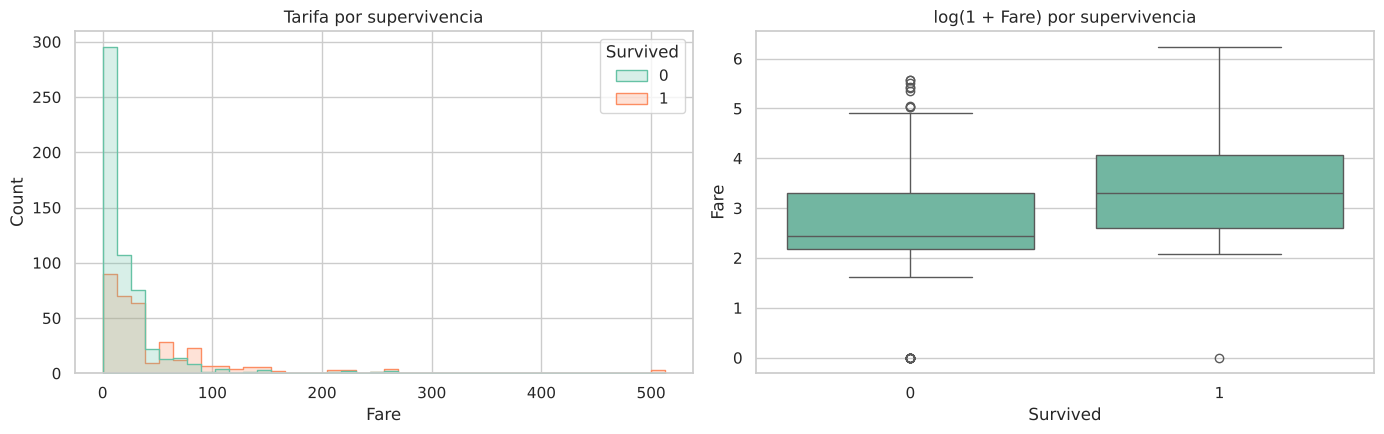

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=df, x="Fare", hue="Survived", bins=40, ax=axes[0], element="step", log_scale=(False, False))
axes[0].set_title("Tarifa por supervivencia")
sns.boxplot(data=df, x="Survived", y=np.log1p(df["Fare"]), ax=axes[1])
axes[1].set_title("log(1 + Fare) por supervivencia")
plt.tight_layout(); plt.show()

Quienes pagaron tarifas más altas sobrevivieron más; `Fare` está muy sesgada a la derecha (por eso se ve mejor en escala logarítmica).

## 2.5 Familia y título

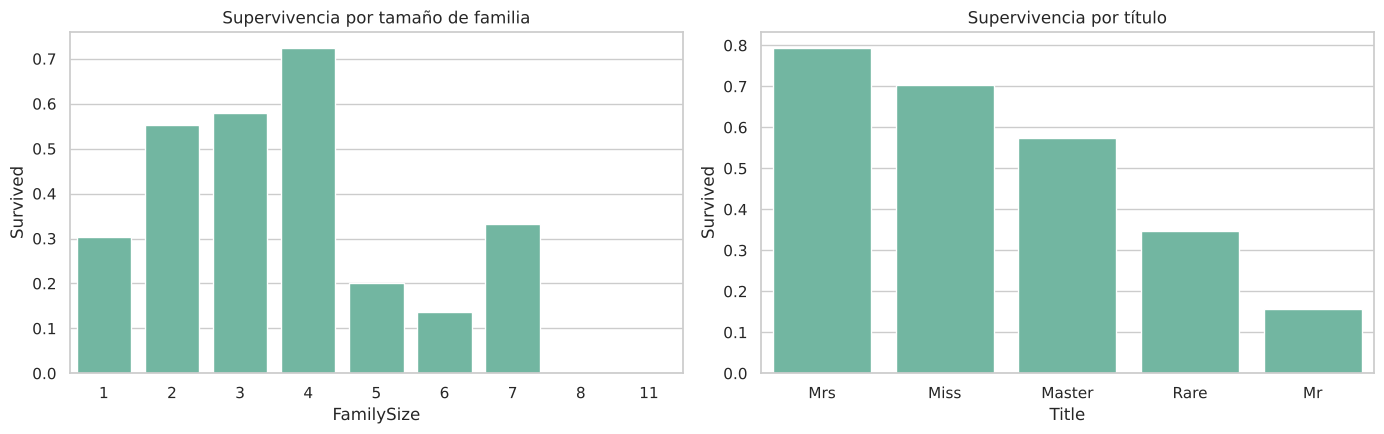

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=df, x="FamilySize", y="Survived", ax=axes[0], errorbar=None)
axes[0].set_title("Supervivencia por tamaño de familia")
sns.barplot(data=df, x="Title", y="Survived", ax=axes[1], errorbar=None,
            order=df.groupby("Title")["Survived"].mean().sort_values(ascending=False).index)
axes[1].set_title("Supervivencia por título")
plt.tight_layout(); plt.show()

- Viajar **solo** (tamaño 1) o en familias **muy grandes** (5+) reduce la supervivencia; las familias de 2 a 4 personas sobreviven más.
- El **título** resume sexo, edad y estatus: "Mrs", "Miss" y "Master" (niños) sobreviven mucho más que "Mr".

## 2.6 Cubierta / cabina

/tmp/ipykernel_508/551539536.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Sin cabina registrada", "Con cabina"])


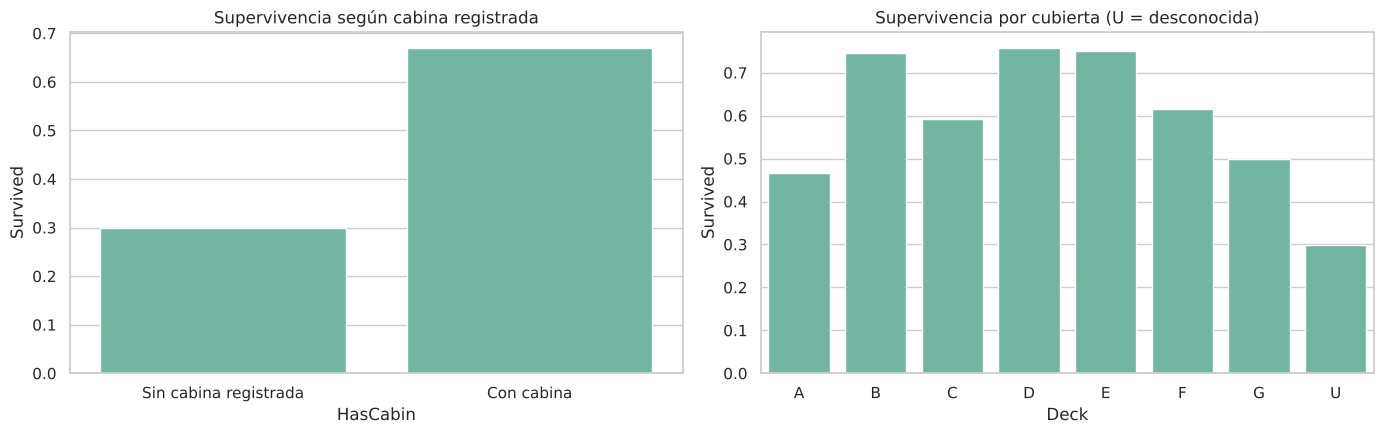

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(data=df, x="HasCabin", y="Survived", ax=axes[0], errorbar=None)
axes[0].set_xticklabels(["Sin cabina registrada", "Con cabina"])
axes[0].set_title("Supervivencia según cabina registrada")
sns.barplot(data=df, x="Deck", y="Survived", ax=axes[1], errorbar=None, order=sorted(df["Deck"].unique()))
axes[1].set_title("Supervivencia por cubierta (U = desconocida)")
plt.tight_layout(); plt.show()

## 2.7 Correlaciones

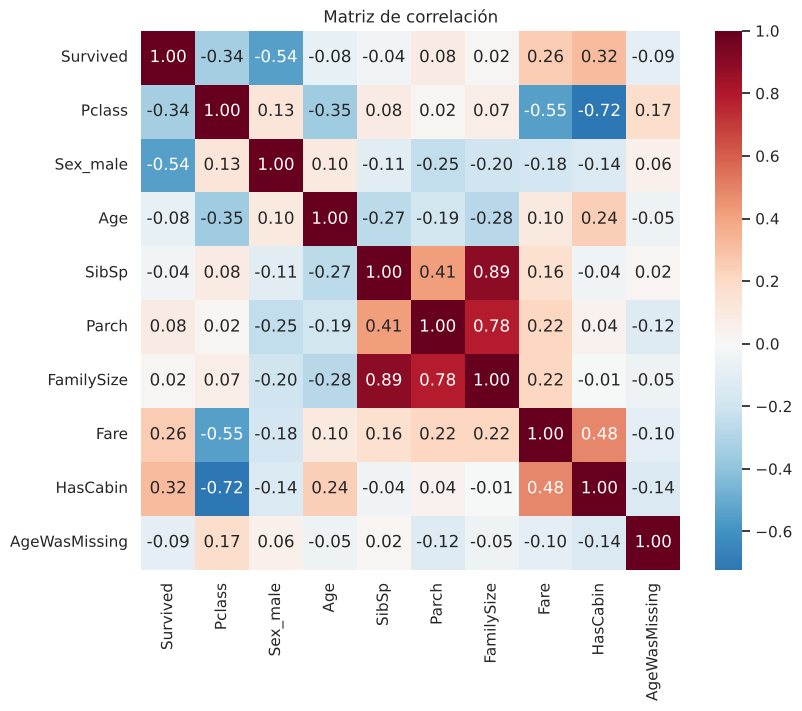

Sex_male        -0.543351
Pclass          -0.338481
HasCabin         0.319572
Fare             0.257307
AgeWasMissing   -0.092197
Parch            0.081629
Age             -0.078931
SibSp           -0.035322
FamilySize       0.016639
Name: Survived, dtype: float64

In [11]:
num = df.assign(Sex_male=(df["Sex"] == "male").astype(int))[
    ["Survived", "Pclass", "Sex_male", "Age", "SibSp", "Parch", "FamilySize", "Fare", "HasCabin", "AgeWasMissing"]]
plt.figure(figsize=(9, 7))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True)
plt.title("Matriz de correlación")
plt.show()

num.corr()["Survived"].drop("Survived").sort_values(key=abs, ascending=False)

## Conclusiones del EDA
1. **Sexo** es la variable más asociada con la supervivencia (correlación negativa fuerte con ser hombre).
2. **Clase**, **tarifa** y **tener cabina** reflejan el estatus socioeconómico, que también aumenta la supervivencia. Están correlacionadas entre sí.
3. La **edad** importa sobre todo en los extremos: los niños sobreviven más.
4. El **tamaño de familia** tiene una relación no lineal (solos y familias grandes, peor). Conviene crear variables como `FamilySize` e `IsAlone`.
5. El **título** concentra información útil de sexo + edad + estatus.

**Siguiente paso:** `3_feature_engineering.ipynb`.